<a href="https://colab.research.google.com/github/PercyTechX/PercyTechX/blob/main/MIA_YOLO_OCR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!nvidia-smi


Tue May 19 00:49:55 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!pip install -q ultralytics easyocr


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 33.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 78.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.7/180.7 kB 20.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 978.2/978.2 kB 55.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 299.6/299.6 kB 31.3 MB/s eta 0:00:00


In [3]:
import torch, ultralytics, easyocr

print(f"PyTorch:     {torch.__version__}")
print(f"CUDA:        {torch.cuda.is_available()} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'N/A'})")
print(f"Ultralytics: {ultralytics.__version__}")
print(f"EasyOCR:     OK")


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
PyTorch:     2.10.0+cu128
CUDA:        True (Tesla T4)
Ultralytics: 8.4.51
EasyOCR:     OK


In [4]:
from google.colab import files
print("Selecciona el archivo best.pt de tu PC...")
uploaded = files.upload()
print("\n✅ Archivos subidos:")
for name in uploaded:
    print(f"  {name} ({len(uploaded[name])/1024/1024:.2f} MB)")


Selecciona el archivo best.pt de tu PC...


Saving best.pt to best.pt

✅ Archivos subidos:
  best.pt (5.22 MB)


In [5]:
!pip install -q roboflow

from getpass import getpass
from roboflow import Roboflow

api_key = getpass("Pega tu Roboflow API key y presiona Enter: ")

rf = Roboflow(api_key=api_key)
project = rf.workspace("tp2-bbjq4").project("peruvian-plate-detection-rbdtj")
version = project.version(2)
dataset = version.download("yolov11")

print("\n✅ Dataset en:", dataset.location)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.9/207.9 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 57.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 106.4 MB/s eta 0:00:00
Pega tu Roboflow API key y presiona Enter: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Peruvian-plate-detection-2 in yolov11:: 100%|██████████| 606/606 [00:00<00:00, 9137.52it/s]


✅ Dataset en: /content/Peruvian-plate-detection-2


In [6]:
import os
from ultralytics import YOLO

# Cargar tu modelo entrenado
model = YOLO("/content/best.pt")
print(f"✅ Modelo cargado: {model.task}, {len(model.names)} clase(s) → {model.names}")

# Comprobar imágenes de test
test_dir = "/content/Peruvian-plate-detection-2/test/images"
test_imgs = sorted(os.listdir(test_dir))
print(f"\n✅ Imágenes de test: {len(test_imgs)}")
print("Primeras 3:")
for f in test_imgs[:3]:
    print(f"  - {f}")


✅ Modelo cargado: detect, 1 clase(s) → {0: 'car-plate'}

✅ Imágenes de test: 21
Primeras 3:
  - IMG-117402_png.rf.8a60e760bcc8fba74ae40b733b06278f.jpg
  - IMG-118887_png.rf.dedf3407d380d39616b56643c07114e1.jpg
  - IMG-19678_png.rf.f189d5ce1537ca94ff81cbb8ce60454c.jpg


In [7]:
import easyocr
reader = easyocr.Reader(['en'], gpu=True)
print("✅ EasyOCR listo (modelo latino, GPU activada)")


Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete✅ EasyOCR listo (modelo latino, GPU activada)


YOLO → caja [135,413,231,495]   conf=0.97   tamaño crop: 96x82px

📖 EasyOCR detectó:
   → 'ANe: 322'  (confianza: 0.15)


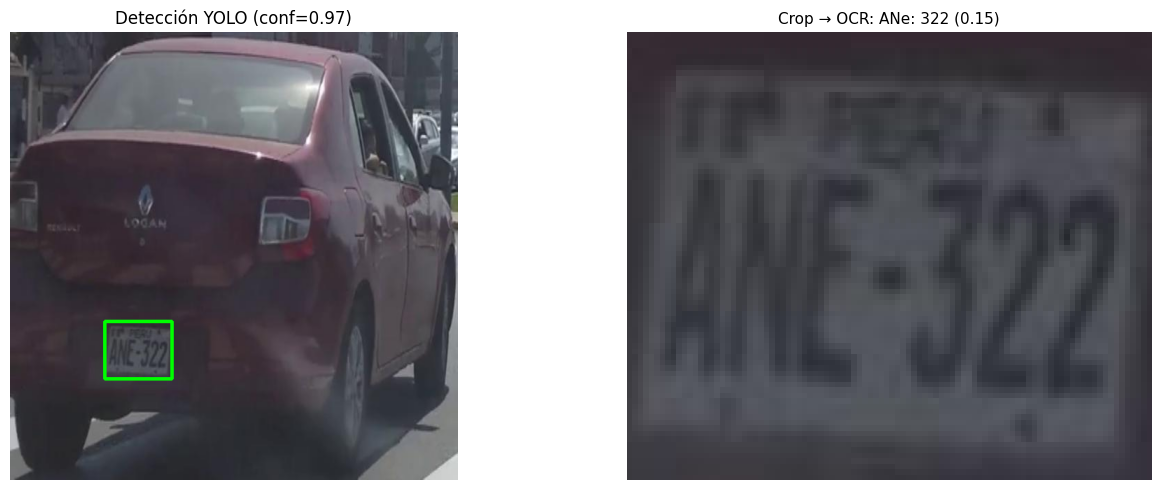

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

# 1. Imagen a probar (la del PDF)
img_path = "/content/Peruvian-plate-detection-2/test/images/img-32229_png.rf.e9c1cad13b7e43c264aec28fd675bc5a.jpg"

# 2. Detección con tu modelo
results = model.predict(img_path, conf=0.25, verbose=False)
r = results[0]
img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)

if len(r.boxes) == 0:
    print("⚠️ No se detectó placa")
else:
    # 3. Recortar la primera placa detectada
    x1, y1, x2, y2 = map(int, r.boxes.xyxy[0].tolist())
    conf_yolo = float(r.boxes.conf[0])
    crop = img[y1:y2, x1:x2]
    print(f"YOLO → caja [{x1},{y1},{x2},{y2}]   conf={conf_yolo:.2f}   tamaño crop: {crop.shape[1]}x{crop.shape[0]}px")

    # 4. OCR sobre el crop (sin preprocesamiento — "naive")
    ocr_results = reader.readtext(crop)

    print("\n📖 EasyOCR detectó:")
    if not ocr_results:
        print("   (nada — el OCR no leyó texto)")
    for (bbox, text, conf_ocr) in ocr_results:
        print(f"   → '{text}'  (confianza: {conf_ocr:.2f})")

    # 5. Visualización
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Imagen original con caja
    img_box = img.copy()
    cv2.rectangle(img_box, (x1, y1), (x2, y2), (0, 255, 0), 3)
    axes[0].imshow(img_box)
    axes[0].set_title(f"Detección YOLO (conf={conf_yolo:.2f})")
    axes[0].axis('off')

    # Crop ampliado con texto OCR
    axes[1].imshow(crop)
    ocr_text = " | ".join([f"{t} ({c:.2f})" for (_, t, c) in ocr_results]) or "(sin lectura)"
    axes[1].set_title(f"Crop → OCR: {ocr_text}", fontsize=11)
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()


In [9]:
import os, glob, re
from collections import Counter

PERU_REGEX = re.compile(r"^[A-Z]{3}-?\d{3}$")  # ABC-123 o ABC123

test_dir = "/content/Peruvian-plate-detection-2/test/images"
test_imgs = sorted(glob.glob(f"{test_dir}/*"))

stats = Counter()
results_log = []

for img_path in test_imgs:
    name = os.path.basename(img_path)[:30]
    yolo_res = model.predict(img_path, conf=0.25, verbose=False)[0]

    if len(yolo_res.boxes) == 0:
        stats["yolo_falla"] += 1
        results_log.append((name, "—", "—", "❌ YOLO no detectó"))
        continue

    # Tomar la primera placa
    x1, y1, x2, y2 = map(int, yolo_res.boxes.xyxy[0].tolist())
    img = cv2.imread(img_path)
    crop = img[y1:y2, x1:x2]

    ocr_results = reader.readtext(crop)
    if not ocr_results:
        stats["ocr_vacio"] += 1
        results_log.append((name, "(vacío)", "0.00", "❌ OCR no leyó"))
        continue

    # Unir todas las cajas de texto encontradas en el crop
    text = "".join([t for (_, t, _) in ocr_results]).upper().replace(" ", "")
    conf = sum([c for (_, _, c) in ocr_results]) / len(ocr_results)
    clean = re.sub(r"[^A-Z0-9]", "", text)  # solo alfanumérico

    if PERU_REGEX.match(clean) or PERU_REGEX.match(clean[:3] + "-" + clean[3:6] if len(clean) >= 6 else ""):
        stats["valido"] += 1
        veredicto = "✅ formato peruano OK"
    else:
        stats["invalido"] += 1
        veredicto = f"⚠️ no encaja formato"

    results_log.append((name, text, f"{conf:.2f}", veredicto))

# Resumen
print(f"{'Imagen':<32} {'Texto leído':<18} {'Conf':<6} Veredicto")
print("-" * 90)
for name, txt, conf, ver in results_log:
    print(f"{name:<32} {txt:<18} {conf:<6} {ver}")

print("\n" + "=" * 50)
print(f"📊 RESUMEN BASELINE (pipeline naive)")
print(f"   ✅ Lecturas con formato peruano: {stats['valido']:>3} / 21  ({100*stats['valido']/21:.0f}%)")
print(f"   ⚠️ Lecturas sin formato válido: {stats['invalido']:>3} / 21")
print(f"   ❌ OCR sin lectura:             {stats['ocr_vacio']:>3} / 21")
print(f"   ❌ YOLO sin detectar:           {stats['yolo_falla']:>3} / 21")


Imagen                           Texto leído        Conf   Veredicto
------------------------------------------------------------------------------------------
IMG-117402_png.rf.8a60e760bcc8   D0347              0.05   ⚠️ no encaja formato
IMG-118887_png.rf.dedf3407d380   PERUS@OIZL3        0.12   ⚠️ no encaja formato
IMG-19678_png.rf.f189d5ce1537c   WUU                0.10   ⚠️ no encaja formato
IMG-22263_png.rf.06b3c435891d6   PERUFFOF347        0.53   ⚠️ no encaja formato
IMG-23528_png.rf.248abeb8da5a7   6LE25              0.06   ⚠️ no encaja formato
IMG-2738_png.rf.fb11cbee12df4d   I03U;34            0.07   ⚠️ no encaja formato
IMG-27565_png.rf.02b174aeecf18   ERUBNK648          0.50   ⚠️ no encaja formato
IMG-27840_png.rf.e02a6238162af   MLG                0.08   ⚠️ no encaja formato
IMG-29908_png.rf.e93a60a4be7a5   (vacío)            0.00   ❌ OCR no leyó
IMG-36860_png.rf.559602af6905d   PERUBCP:338        0.15   ⚠️ no encaja formato
IMG-50698_png.rf.e7b79c91686ee   EORI3O        

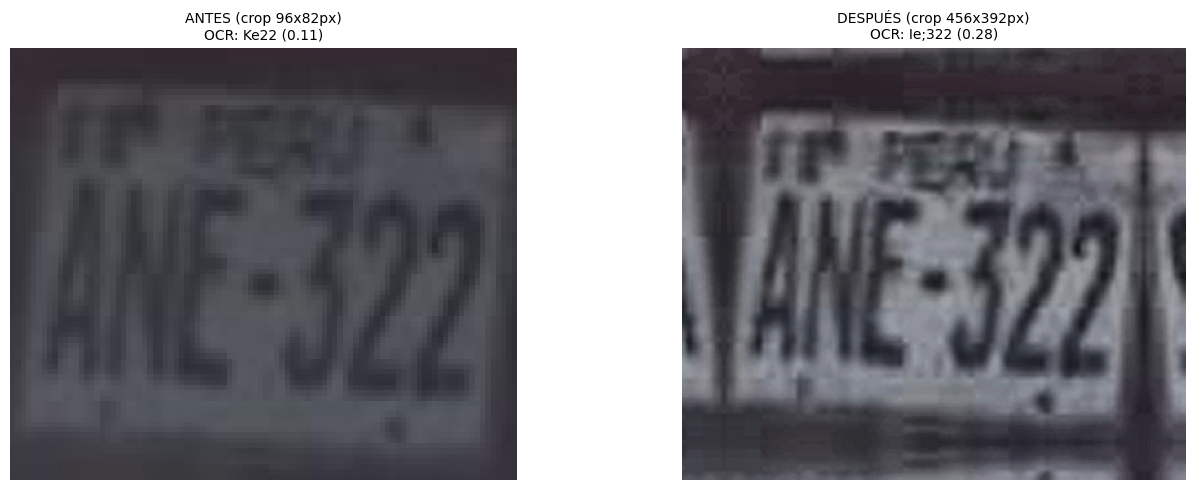


Antes:   Ke22 (0.11)
Después: Ie;322 (0.28)


In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def preprocess_plate(crop_bgr, pad_pct=0.10, upscale=4):
    """
    Mejora un crop de placa para OCR:
      1. Añade padding para no recortar letras
      2. Upscale con INTER_CUBIC (super-res barata)
      3. CLAHE en LAB (contraste local)
      4. Unsharp mask (bordes nítidos)
    """
    h, w = crop_bgr.shape[:2]

    # 1. Padding (rellena con borde reflejado, no negro)
    pad_h, pad_w = int(h * pad_pct), int(w * pad_pct)
    padded = cv2.copyMakeBorder(crop_bgr, pad_h, pad_h, pad_w, pad_w,
                                 cv2.BORDER_REFLECT_101)

    # 2. Upscale
    big = cv2.resize(padded, None, fx=upscale, fy=upscale,
                     interpolation=cv2.INTER_CUBIC)

    # 3. CLAHE en canal L (preserva color)
    lab = cv2.cvtColor(big, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8))
    l = clahe.apply(l)
    enhanced = cv2.merge([l, a, b])
    enhanced = cv2.cvtColor(enhanced, cv2.COLOR_LAB2BGR)

    # 4. Unsharp mask (sharpen suave)
    blur = cv2.GaussianBlur(enhanced, (0, 0), sigmaX=2)
    sharp = cv2.addWeighted(enhanced, 1.5, blur, -0.5, 0)

    return sharp


# ----- Comparación visual sobre la imagen del PDF -----
img_path = "/content/Peruvian-plate-detection-2/test/images/img-32229_png.rf.e9c1cad13b7e43c264aec28fd675bc5a.jpg"
img = cv2.imread(img_path)
r = model.predict(img_path, conf=0.25, verbose=False)[0]
x1, y1, x2, y2 = map(int, r.boxes.xyxy[0].tolist())
crop = img[y1:y2, x1:x2]

# Crop procesado
crop_pp = preprocess_plate(crop)

# OCR sobre ambos
ocr_naive = reader.readtext(crop)
ocr_pp    = reader.readtext(crop_pp)

txt_naive = " | ".join([f"{t} ({c:.2f})" for (_, t, c) in ocr_naive]) or "(sin lectura)"
txt_pp    = " | ".join([f"{t} ({c:.2f})" for (_, t, c) in ocr_pp])    or "(sin lectura)"

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"ANTES (crop {crop.shape[1]}x{crop.shape[0]}px)\nOCR: {txt_naive}", fontsize=10)
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(crop_pp, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"DESPUÉS (crop {crop_pp.shape[1]}x{crop_pp.shape[0]}px)\nOCR: {txt_pp}", fontsize=10)
axes[1].axis('off')

plt.tight_layout()
plt.show()

print(f"\nAntes:   {txt_naive}")
print(f"Después: {txt_pp}")


In [11]:
import re, os, glob
from collections import Counter

PERU_REGEX = re.compile(r"^[A-Z]{3}-?\d{3}$")
ALLOWLIST = "ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789-"

def clean_ocr_text(ocr_results):
    """
    Une las cajas de texto que EasyOCR devuelve, filtra 'PERU'
    (parte del template), y deja solo alfanuméricos en mayúsculas.
    """
    out = []
    for (_, text, conf) in ocr_results:
        t = text.upper().replace(" ", "").replace("-", "")
        # Eliminar el sello "PERU" o variantes truncadas
        for tpl in ["PERU", "PERV", "ERU", "PER"]:
            if t.startswith(tpl):
                t = t[len(tpl):]
                break
        t = re.sub(r"[^A-Z0-9]", "", t)
        if t:
            out.append((t, conf))
    return out

def try_format_peru(raw):
    """Intenta encajar el texto en patrón ABC-123."""
    if len(raw) >= 6:
        candidate = raw[:3] + "-" + raw[3:6]
        if PERU_REGEX.match(candidate):
            return candidate
    return None

# ---- Loop sobre las 21 imágenes ----
test_dir = "/content/Peruvian-plate-detection-2/test/images"
test_imgs = sorted(glob.glob(f"{test_dir}/*"))

stats = Counter()
results_log = []

for img_path in test_imgs:
    name = os.path.basename(img_path)[:30]
    img = cv2.imread(img_path)
    r = model.predict(img_path, conf=0.25, verbose=False)[0]

    if len(r.boxes) == 0:
        stats["yolo_falla"] += 1
        results_log.append((name, "—", "—", "❌ YOLO no detectó"))
        continue

    x1, y1, x2, y2 = map(int, r.boxes.xyxy[0].tolist())
    crop = img[y1:y2, x1:x2]

    # ★ Preprocesamiento
    crop_pp = preprocess_plate(crop)

    # ★ EasyOCR con allowlist
    ocr_raw = reader.readtext(crop_pp, allowlist=ALLOWLIST,
                              text_threshold=0.5, low_text=0.3)

    cleaned = clean_ocr_text(ocr_raw)
    if not cleaned:
        stats["ocr_vacio"] += 1
        results_log.append((name, "(vacío)", "0.00", "❌ OCR no leyó"))
        continue

    # Tomar el texto más largo (suele ser el número de placa real)
    cleaned.sort(key=lambda x: (-len(x[0]), -x[1]))
    best_text, best_conf = cleaned[0]

    formatted = try_format_peru(best_text)
    if formatted:
        stats["valido"] += 1
        veredicto = f"✅ {formatted}"
    else:
        stats["invalido"] += 1
        veredicto = "⚠️ no encaja formato"

    results_log.append((name, best_text, f"{best_conf:.2f}", veredicto))

# ---- Salida ----
print(f"{'Imagen':<32} {'Texto leído':<14} {'Conf':<6} Veredicto")
print("-" * 80)
for name, txt, conf, ver in results_log:
    print(f"{name:<32} {txt:<14} {conf:<6} {ver}")

print("\n" + "=" * 50)
print(f"📊 RESULTADO FASE 2 (preprocesamiento + allowlist)")
print(f"   ✅ Lecturas con formato peruano: {stats['valido']:>3} / 21  ({100*stats['valido']/21:.0f}%)")
print(f"   ⚠️ Lecturas sin formato válido: {stats['invalido']:>3} / 21")
print(f"   ❌ OCR sin lectura:             {stats['ocr_vacio']:>3} / 21")
print(f"   ❌ YOLO sin detectar:           {stats['yolo_falla']:>3} / 21")
print("\n📈 Comparación con baseline:")
print(f"   Antes (Fase 1 naive):  0 / 21  (0%)")
print(f"   Ahora (Fase 2):        {stats['valido']} / 21  ({100*stats['valido']/21:.0f}%)")


Imagen                           Texto leído    Conf   Veredicto
--------------------------------------------------------------------------------
IMG-117402_png.rf.8a60e760bcc8   BI34           0.07   ⚠️ no encaja formato
IMG-118887_png.rf.dedf3407d380   WI             0.05   ⚠️ no encaja formato
IMG-19678_png.rf.f189d5ce1537c   KZ             0.14   ⚠️ no encaja formato
IMG-22263_png.rf.06b3c435891d6   JF663T         0.17   ⚠️ no encaja formato
IMG-23528_png.rf.248abeb8da5a7   IZ             0.89   ⚠️ no encaja formato
IMG-2738_png.rf.fb11cbee12df4d   WIE            0.44   ⚠️ no encaja formato
IMG-27565_png.rf.02b174aeecf18   BMB8E          0.10   ⚠️ no encaja formato
IMG-27840_png.rf.e02a6238162af   RO5V           0.06   ⚠️ no encaja formato
IMG-29908_png.rf.e93a60a4be7a5   23             0.05   ⚠️ no encaja formato
IMG-36860_png.rf.559602af6905d   EPI8E          0.11   ⚠️ no encaja formato
IMG-50698_png.rf.e7b79c91686ee   EBRI7          0.03   ⚠️ no encaja formato
IMG-52832_png.rf.f

In [12]:
import re, os, glob
from collections import Counter

# Confusiones típicas OCR (dígito → letra y viceversa)
DIGIT_TO_LETTER = {'0':'O', '1':'I', '2':'Z', '5':'S', '6':'G', '8':'B'}
LETTER_TO_DIGIT = {'O':'0', 'I':'1', 'Z':'2', 'S':'5', 'G':'6', 'B':'8',
                   'D':'0', 'Q':'0', 'L':'1', 'T':'1'}

PERU_REGEX = re.compile(r"^[A-Z]{3}-?\d{3}$")
ALLOWLIST = "ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789-"

def corregir_por_posicion(candidato6):
    """
    Aplica las reglas peruanas:
      - Posiciones 0,1,2 → deben ser LETRAS  (si vienen dígitos, los corrige)
      - Posiciones 3,4,5 → deben ser DÍGITOS (si vienen letras, los corrige)
    Devuelve placa con guión o None si no es recuperable.
    """
    if len(candidato6) != 6:
        return None

    letras = ""
    for ch in candidato6[:3]:
        if ch.isalpha():
            letras += ch
        elif ch in DIGIT_TO_LETTER:
            letras += DIGIT_TO_LETTER[ch]
        else:
            return None  # carácter irrecuperable

    digitos = ""
    for ch in candidato6[3:]:
        if ch.isdigit():
            digitos += ch
        elif ch in LETTER_TO_DIGIT:
            digitos += LETTER_TO_DIGIT[ch]
        else:
            return None

    placa = f"{letras}-{digitos}"
    return placa if PERU_REGEX.match(placa) else None


def parse_placa_peruana(ocr_results):
    """
    Toma TODAS las cajas que EasyOCR encontró, las concatena,
    limpia 'PERU' y otros tokens del template, y busca con sliding
    window una placa peruana válida (aplicando corrección por posición).
    """
    # Concatenar todas las lecturas
    bruto = "".join([t for (_, t, _) in ocr_results]).upper()
    bruto = re.sub(r"[^A-Z0-9]", "", bruto)

    # Filtrar la palabra "PERU" y variantes
    for tpl in ["PERU", "PERV", "ERU", "PER"]:
        bruto = bruto.replace(tpl, "")

    # Sliding window de tamaño 6
    mejor = None
    for i in range(len(bruto) - 5):
        ventana = bruto[i:i+6]
        placa = corregir_por_posicion(ventana)
        if placa:
            return placa, bruto  # tomamos la primera válida
    return None, bruto


# ---- Loop sobre las 21 imágenes con TODO el pipeline ----
test_dir = "/content/Peruvian-plate-detection-2/test/images"
test_imgs = sorted(glob.glob(f"{test_dir}/*"))

stats = Counter()
results_log = []

for img_path in test_imgs:
    name = os.path.basename(img_path)[:30]
    img = cv2.imread(img_path)
    r = model.predict(img_path, conf=0.25, verbose=False)[0]

    if len(r.boxes) == 0:
        stats["yolo_falla"] += 1
        results_log.append((name, "—", "—", "❌ YOLO no detectó"))
        continue

    x1, y1, x2, y2 = map(int, r.boxes.xyxy[0].tolist())
    crop = img[y1:y2, x1:x2]
    crop_pp = preprocess_plate(crop)

    ocr_raw = reader.readtext(crop_pp, allowlist=ALLOWLIST,
                              text_threshold=0.5, low_text=0.3)

    placa, bruto = parse_placa_peruana(ocr_raw)

    if placa:
        stats["valido"] += 1
        results_log.append((name, bruto[:14], f"→ {placa}", "✅"))
    elif bruto:
        stats["invalido"] += 1
        results_log.append((name, bruto[:14], "—", "⚠️ no recuperable"))
    else:
        stats["ocr_vacio"] += 1
        results_log.append((name, "(vacío)", "—", "❌ OCR no leyó"))

# ---- Salida ----
print(f"{'Imagen':<32} {'OCR bruto':<16} {'Placa final':<14} Veredicto")
print("-" * 80)
for name, txt, placa, ver in results_log:
    print(f"{name:<32} {txt:<16} {placa:<14} {ver}")

print("\n" + "=" * 60)
print(f"📊 RESULTADO FASE 3 (preprocesamiento + corrección posicional)")
print(f"   ✅ Placas recuperadas:    {stats['valido']:>3} / 21  ({100*stats['valido']/21:.0f}%)")
print(f"   ⚠️ OCR ilegible/parcial: {stats['invalido']:>3} / 21")
print(f"   ❌ OCR vacío:            {stats['ocr_vacio']:>3} / 21")
print(f"   ❌ YOLO no detectó:      {stats['yolo_falla']:>3} / 21")
print()
print(f"📈 Evolución del pipeline:")
print(f"   Fase 1 (naive):                       0 / 21  (0%)")
print(f"   Fase 2 (preprocesamiento + allowlist): 0 / 21  (0%)")
print(f"   Fase 3 (regex + corrección):          {stats['valido']} / 21  ({100*stats['valido']/21:.0f}%)")
print(f"\n   Sobre placas DETECTADAS por YOLO (17): {stats['valido']} / 17  ({100*stats['valido']/17:.0f}%)")


Imagen                           OCR bruto        Placa final    Veredicto
--------------------------------------------------------------------------------
IMG-117402_png.rf.8a60e760bcc8   BI34             —              ⚠️ no recuperable
IMG-118887_png.rf.dedf3407d380   WI               —              ⚠️ no recuperable
IMG-19678_png.rf.f189d5ce1537c   KZ               —              ⚠️ no recuperable
IMG-22263_png.rf.06b3c435891d6   PJF663T          → PJF-663      ✅
IMG-23528_png.rf.248abeb8da5a7   IZ               —              ⚠️ no recuperable
IMG-2738_png.rf.fb11cbee12df4d   WIE              —              ⚠️ no recuperable
IMG-27565_png.rf.02b174aeecf18   IBMB8ETVLO0LUT   → ETV-100      ✅
IMG-27840_png.rf.e02a6238162af   RO5V             —              ⚠️ no recuperable
IMG-29908_png.rf.e93a60a4be7a5   23               —              ⚠️ no recuperable
IMG-36860_png.rf.559602af6905d   3EPI8E           —              ⚠️ no recuperable
IMG-50698_png.rf.e7b79c91686ee   EBRI7        

In [13]:
import re, os, glob
from collections import Counter

def generar_variantes(crop_bgr, upscale=4):
    """Devuelve 3 versiones preprocesadas del crop para OCR ensemble."""
    h, w = crop_bgr.shape[:2]
    pad_h, pad_w = int(h * 0.20), int(w * 0.20)  # 20% padding
    padded = cv2.copyMakeBorder(crop_bgr, pad_h, pad_h, pad_w, pad_w,
                                 cv2.BORDER_REFLECT_101)
    big = cv2.resize(padded, None, fx=upscale, fy=upscale,
                     interpolation=cv2.INTER_CUBIC)

    # Variante 1: CLAHE en color + sharpen
    lab = cv2.cvtColor(big, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    l = clahe.apply(l)
    v1 = cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2BGR)
    blur = cv2.GaussianBlur(v1, (0, 0), 2)
    v1 = cv2.addWeighted(v1, 1.5, blur, -0.5, 0)

    # Variante 2: escala de grises + CLAHE
    gray = cv2.cvtColor(big, cv2.COLOR_BGR2GRAY)
    v2 = clahe.apply(gray)

    # Variante 3: gris + threshold adaptativo (texto negro sobre blanco)
    v3 = cv2.adaptiveThreshold(v2, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                cv2.THRESH_BINARY, 15, 8)

    return [v1, v2, v3]

def multi_ocr(crop_bgr):
    """Corre OCR sobre 3 variantes y concatena TODO el texto detectado."""
    variantes = generar_variantes(crop_bgr)
    todos_textos = []
    for v in variantes:
        results = reader.readtext(
            v,
            allowlist=ALLOWLIST,
            text_threshold=0.3,   # ← más permisivo (default 0.7)
            low_text=0.2,         # ← más permisivo (default 0.4)
            link_threshold=0.2,   # ← une cajas separadas (default 0.4)
            min_size=5,           # ← acepta texto chiquito
        )
        todos_textos.extend([t for (_, t, _) in results])
    return "".join(todos_textos).upper()

def parse_placa_v2(texto_concat):
    """Limpia + sliding window con corrección por posición."""
    bruto = re.sub(r"[^A-Z0-9]", "", texto_concat)
    for tpl in ["PERU", "PERV", "ERU", "PER"]:
        bruto = bruto.replace(tpl, "")
    if len(bruto) < 6:
        return None, bruto
    for i in range(len(bruto) - 5):
        placa = corregir_por_posicion(bruto[i:i+6])
        if placa:
            return placa, bruto
    return None, bruto

# ---- Loop ----
stats = Counter()
results_log = []

for img_path in test_imgs:
    name = os.path.basename(img_path)[:30]
    img = cv2.imread(img_path)
    r = model.predict(img_path, conf=0.25, verbose=False)[0]

    if len(r.boxes) == 0:
        stats["yolo_falla"] += 1
        results_log.append((name, "—", "—", "❌ YOLO no detectó"))
        continue

    x1, y1, x2, y2 = map(int, r.boxes.xyxy[0].tolist())
    crop = img[y1:y2, x1:x2]

    bruto = multi_ocr(crop)
    placa, limpio = parse_placa_v2(bruto)

    if placa:
        stats["valido"] += 1
        results_log.append((name, limpio[:18], f"→ {placa}", "✅"))
    elif limpio:
        stats["invalido"] += 1
        results_log.append((name, limpio[:18], "—", "⚠️"))
    else:
        stats["ocr_vacio"] += 1
        results_log.append((name, "(vacío)", "—", "❌"))

# ---- Salida ----
print(f"{'Imagen':<32} {'OCR concatenado':<20} {'Placa final':<14} V")
print("-" * 80)
for name, txt, placa, ver in results_log:
    print(f"{name:<32} {txt:<20} {placa:<14} {ver}")

print("\n" + "=" * 60)
print(f"📊 RESULTADO FASE 3b (multi-variant OCR + umbrales laxos)")
print(f"   ✅ Placas recuperadas:    {stats['valido']:>3} / 21  ({100*stats['valido']/21:.0f}%)")
print(f"   ⚠️ OCR ilegible/parcial: {stats['invalido']:>3} / 21")
print(f"   ❌ OCR vacío:            {stats['ocr_vacio']:>3} / 21")
print(f"   ❌ YOLO no detectó:      {stats['yolo_falla']:>3} / 21")
print()
print(f"📈 Evolución del pipeline:")
print(f"   Fase 1 (naive):                       0 / 21  (0%)")
print(f"   Fase 2 (preprocesamiento + allowlist): 0 / 21  (0%)")
print(f"   Fase 3 (regex + corrección):          4 / 21  (19%)")
print(f"   Fase 3b (multi-variant + laxo):       {stats['valido']} / 21  ({100*stats['valido']/21:.0f}%)")
print(f"\n   Sobre placas DETECTADAS por YOLO (17): {stats['valido']} / 17  ({100*stats['valido']/17:.0f}%)")


Imagen                           OCR concatenado      Placa final    V
--------------------------------------------------------------------------------
IMG-117402_png.rf.8a60e760bcc8   9BU539BU3I7640YTJX   → BUS-398      ✅
IMG-118887_png.rf.dedf3407d380   AMEAI2318JIKKL5FEI   → MEA-123      ✅
IMG-19678_png.rf.f189d5ce1537c   IWM04LMHL1TI044      → IWM-041      ✅
IMG-22263_png.rf.06b3c435891d6   DCD0E5L2LDE52704M4   → DOE-512      ✅
IMG-23528_png.rf.248abeb8da5a7   JIZIMUJLLUI          —              ⚠️
IMG-2738_png.rf.fb11cbee12df4d   J5I5L64M             → JSI-516      ✅
IMG-27565_png.rf.02b174aeecf18   TOUB18188531DD1618   → TOU-818      ✅
IMG-27840_png.rf.e02a6238162af   MO10MOT414V          → IOM-014      ✅
IMG-29908_png.rf.e93a60a4be7a5   U616                 —              ⚠️
IMG-36860_png.rf.559602af6905d   CAA0I3PCA4DPI80212   → CAA-013      ✅
IMG-50698_png.rf.e7b79c91686ee   9IERIZ0S9IEORIJ0FL   → IER-120      ✅
IMG-52832_png.rf.f09823dfb82e6   8B3I48084B3I4884YA   → BOB-483  

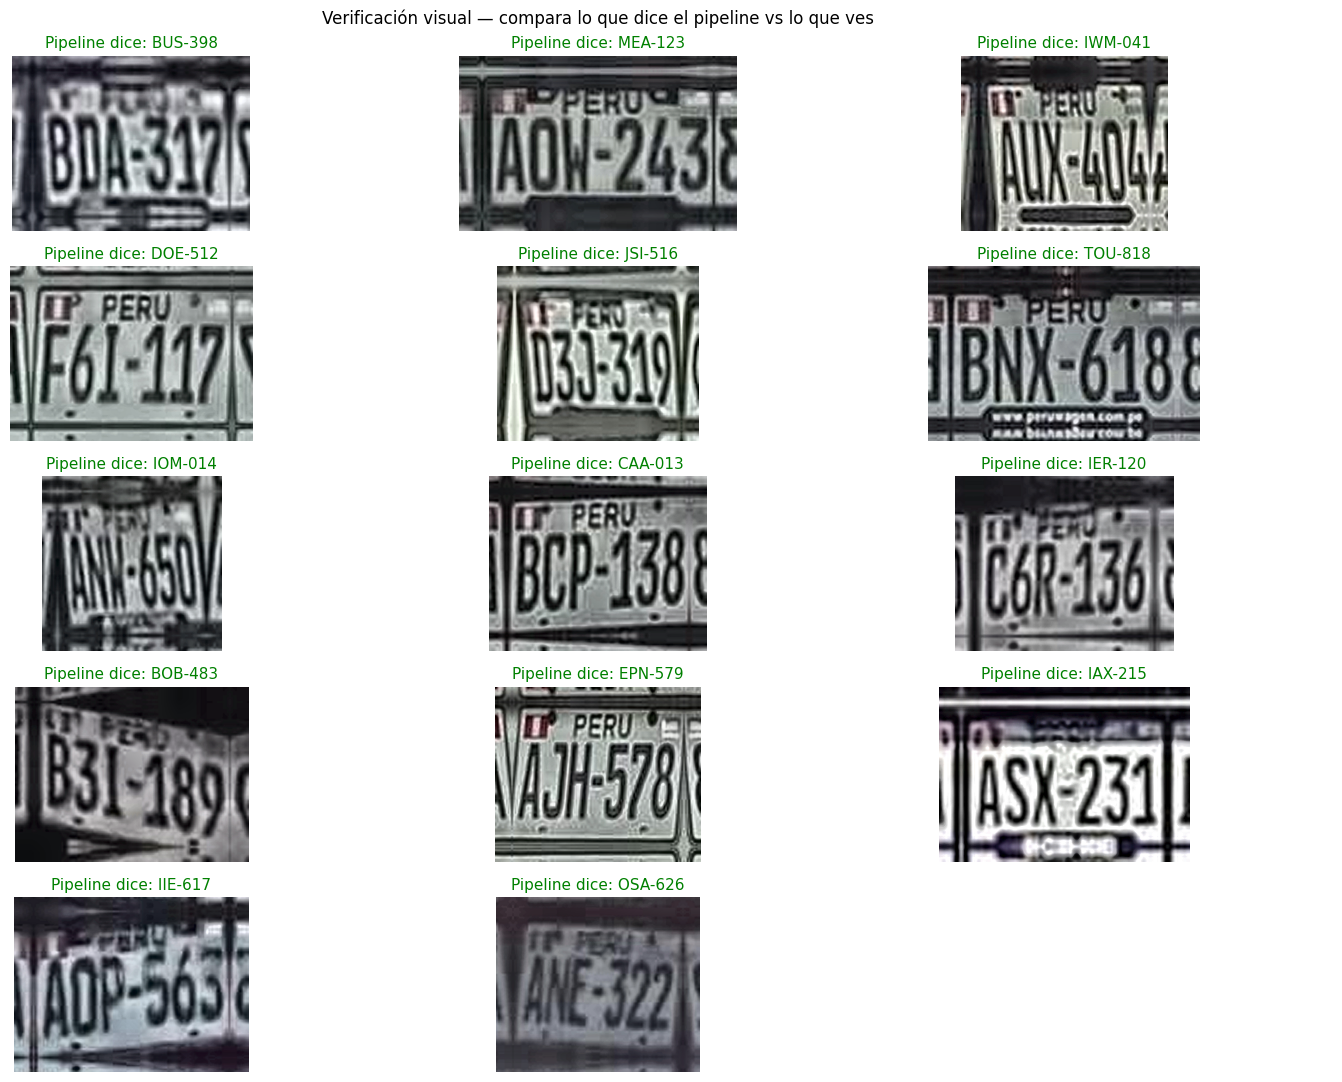

In [15]:
import matplotlib.pyplot as plt

# Re-ejecutar el pipeline guardando crops y lecturas
visualizar = []
for img_path in test_imgs:
    img = cv2.imread(img_path)
    r = model.predict(img_path, conf=0.25, verbose=False)[0]
    if len(r.boxes) == 0:
        continue
    x1, y1, x2, y2 = map(int, r.boxes.xyxy[0].tolist())
    crop = img[y1:y2, x1:x2]
    bruto = multi_ocr(crop)
    placa, _ = parse_placa_v2(bruto)
    if placa:
        visualizar.append((os.path.basename(img_path), crop, placa))

# Grid de las 14 placas leídas
n = len(visualizar)
cols = 3
rows = (n + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 2.2))
axes = axes.flatten() if rows > 1 else [axes] if cols == 1 else axes

for i, (name, crop, placa) in enumerate(visualizar):
    # Mostrar crop preprocesado (más legible)
    crop_pp = preprocess_plate(crop)
    axes[i].imshow(cv2.cvtColor(crop_pp, cv2.COLOR_BGR2RGB))
    axes[i].set_title(f"Pipeline dice: {placa}", fontsize=11, color='green')
    axes[i].axis('off')

# Apagar ejes sobrantes
for j in range(n, len(axes)):
    axes[j].axis('off')

plt.suptitle("Verificación visual — compara lo que dice el pipeline vs lo que ves", fontsize=12)
plt.tight_layout()
plt.show()


Instalar y cargar Qwen2.5-VL-3B

In [16]:
!pip install -q transformers accelerate
!pip install -q qwen-vl-utils


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.3/36.3 MB 21.8 MB/s eta 0:00:00


Verificar que importa todo

In [17]:
import torch
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor
from qwen_vl_utils import process_vision_info

print(f"✅ Transformers y qwen-vl-utils OK")
print(f"   PyTorch: {torch.__version__}")
print(f"   CUDA disponible: {torch.cuda.is_available()}")
print(f"   VRAM libre: {torch.cuda.mem_get_info()[0]/1e9:.1f} GB de {torch.cuda.mem_get_info()[1]/1e9:.1f} GB")


✅ Transformers y qwen-vl-utils OK
   PyTorch: 2.10.0+cu128
   CUDA disponible: True
   VRAM libre: 14.4 GB de 15.6 GB


Descargar y cargar el modelo

In [18]:
MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"

print(f"⏳ Cargando {MODEL_ID} (puede tomar 2-3 min la primera vez)...")

vlm = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.bfloat16,
    device_map="auto",
)
processor = AutoProcessor.from_pretrained(MODEL_ID)

print(f"\n✅ Modelo cargado")
print(f"   VRAM ocupada por VLM: ~{torch.cuda.memory_allocated()/1e9:.1f} GB")
print(f"   VRAM libre restante:  ~{torch.cuda.mem_get_info()[0]/1e9:.1f} GB")


⏳ Cargando Qwen/Qwen2.5-VL-3B-Instruct (puede tomar 2-3 min la primera vez)...



The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.


config.json: 0.00B [00:00, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

...

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]


✅ Modelo cargado
   VRAM ocupada por VLM: ~7.7 GB
   VRAM libre restante:  ~7.7 GB


 Definir la función + probar en la imagen del PDF


The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Crop original: 96×82 px
⏳ Consultando Qwen2.5-VL...

🤖 VLM respondió: 'ANE-322'
⏱️  Tiempo: 7.18 s


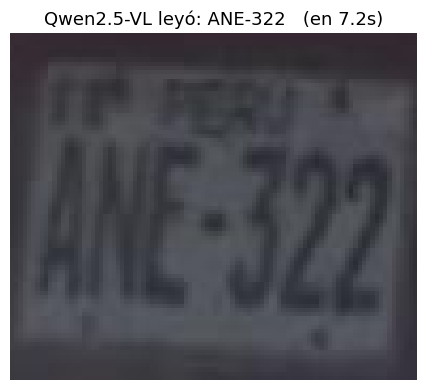

In [19]:
from PIL import Image

def read_plate_vlm(crop_bgr, pad_pct=0.15):
    """
    Pasa el crop al VLM con prompt específico para placas peruanas.
    El VLM es robusto al ruido/iluminación, solo le damos un poco de padding.
    """
    # Padding suave (le da contexto al modelo)
    h, w = crop_bgr.shape[:2]
    pad_h, pad_w = int(h * pad_pct), int(w * pad_pct)
    padded = cv2.copyMakeBorder(crop_bgr, pad_h, pad_h, pad_w, pad_w,
                                 cv2.BORDER_REFLECT_101)

    # BGR -> RGB -> PIL (el processor de Qwen pide PIL)
    pil_img = Image.fromarray(cv2.cvtColor(padded, cv2.COLOR_BGR2RGB))

    # Mensaje con visión + instrucción clara
    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": pil_img},
            {"type": "text", "text":
             "This is a cropped image of a Peruvian vehicle license plate. "
             "Read ONLY the plate number. The format is exactly 3 uppercase "
             "letters + a dash + 3 digits, like ABC-123. "
             "Respond with ONLY the plate number, no explanation. "
             "If you cannot read it confidently, respond with UNREADABLE."}
        ]
    }]

    # Preparar inputs
    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    image_inputs, _ = process_vision_info(messages)
    inputs = processor(text=[text], images=image_inputs, padding=True,
                       return_tensors="pt").to(vlm.device)

    # Generar (greedy, máx 20 tokens — suficiente para "ABC-123")
    with torch.no_grad():
        out_ids = vlm.generate(**inputs, max_new_tokens=20, do_sample=False)
    out_ids = [o[len(i):] for i, o in zip(inputs.input_ids, out_ids)]
    response = processor.batch_decode(out_ids, skip_special_tokens=True)[0].strip()

    return response


# ---- Prueba en la imagen del PDF ----
img_path = "/content/Peruvian-plate-detection-2/test/images/img-32229_png.rf.e9c1cad13b7e43c264aec28fd675bc5a.jpg"
img = cv2.imread(img_path)
r = model.predict(img_path, conf=0.25, verbose=False)[0]
x1, y1, x2, y2 = map(int, r.boxes.xyxy[0].tolist())
crop = img[y1:y2, x1:x2]

print(f"Crop original: {crop.shape[1]}×{crop.shape[0]} px")
print("⏳ Consultando Qwen2.5-VL...")

import time
t0 = time.time()
plate_vlm = read_plate_vlm(crop)
dt = time.time() - t0

print(f"\n🤖 VLM respondió: '{plate_vlm}'")
print(f"⏱️  Tiempo: {dt:.2f} s")

# Visualización
fig, ax = plt.subplots(1, 1, figsize=(8, 4))
ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
ax.set_title(f"Qwen2.5-VL leyó: {plate_vlm}   (en {dt:.1f}s)", fontsize=13)
ax.axis('off')
plt.tight_layout()
plt.show()


Loop sobre las 21 imágenes


In [20]:
import re, time
from collections import Counter

# Regex flexible para extraer cualquier patrón ABC-123 de la respuesta del VLM
PERU_PATTERN = re.compile(r"([A-Z]{3})[\s\-]?(\d{3})")

stats = Counter()
results_log = []
tiempos = []
start_total = time.time()

for idx, img_path in enumerate(test_imgs, 1):
    name = os.path.basename(img_path)[:30]
    img = cv2.imread(img_path)
    r = model.predict(img_path, conf=0.25, verbose=False)[0]

    if len(r.boxes) == 0:
        stats["yolo_falla"] += 1
        results_log.append((name, "—", "—", "❌ YOLO no detectó"))
        continue

    x1, y1, x2, y2 = map(int, r.boxes.xyxy[0].tolist())
    crop = img[y1:y2, x1:x2]

    t0 = time.time()
    respuesta = read_plate_vlm(crop)
    dt = time.time() - t0
    tiempos.append(dt)

    # Intentar extraer ABC-123 de la respuesta
    match = PERU_PATTERN.search(respuesta.upper())
    if match:
        placa = f"{match.group(1)}-{match.group(2)}"
        stats["valido"] += 1
        results_log.append((name, respuesta[:20], f"→ {placa}", f"✅ ({dt:.1f}s)"))
    elif "UNREADABLE" in respuesta.upper():
        stats["unreadable"] += 1
        results_log.append((name, respuesta[:20], "—", f"⚠️ VLM no pudo ({dt:.1f}s)"))
    else:
        stats["invalido"] += 1
        results_log.append((name, respuesta[:20], "—", f"⚠️ formato raro ({dt:.1f}s)"))

    print(f"  [{idx:2d}/21] {dt:.1f}s — {respuesta[:30]}")

total_time = time.time() - start_total

# ---- Tabla final ----
print(f"\n{'Imagen':<32} {'VLM dice':<22} {'Placa':<12} Veredicto")
print("-" * 90)
for name, txt, placa, ver in results_log:
    print(f"{name:<32} {txt:<22} {placa:<12} {ver}")

# ---- Resumen ----
detectadas = 21 - stats['yolo_falla']
print("\n" + "=" * 60)
print(f"📊 RESULTADO QWEN2.5-VL")
print(f"   ✅ Placas leídas (formato OK):   {stats['valido']:>3} / 21  ({100*stats['valido']/21:.0f}%)")
print(f"   ⚠️ VLM dijo 'UNREADABLE':       {stats['unreadable']:>3} / 21")
print(f"   ⚠️ Respuesta sin formato:       {stats['invalido']:>3} / 21")
print(f"   ❌ YOLO no detectó:             {stats['yolo_falla']:>3} / 21")
print()
print(f"⏱️  Tiempo total: {total_time:.1f} s   |  Promedio: {sum(tiempos)/len(tiempos):.1f} s/placa")
print()
print(f"📈 Comparativa final:")
print(f"   Fase 1  (EasyOCR naive):                       0 / 21  (0%)")
print(f"   Fase 2  (EasyOCR + preprocesamiento):          0 / 21  (0%)")
print(f"   Fase 3  (EasyOCR + regex + corrección):        4 / 21  (19%)")
print(f"   Fase 3b (EasyOCR multi-variant):              14 / 21  (67%)")
print(f"   Fase 4  (Qwen2.5-VL):                         {stats['valido']:>2} / 21  ({100*stats['valido']/21:.0f}%)")
print(f"\n   Sobre placas DETECTADAS por YOLO ({detectadas}): {stats['valido']} / {detectadas}  ({100*stats['valido']/max(detectadas,1):.0f}%)")


  [ 1/21] 1.1s — BDA-3175
  [ 2/21] 1.0s — AOH-2438
  [ 3/21] 1.0s — AUX-6044
  [ 4/21] 1.2s — F6I-117
  [ 5/21] 1.2s — AXAE-2500
  [ 6/21] 0.7s — UNREADABLE
  [ 7/21] 1.0s — BNX-6188
  [ 8/21] 0.9s — ANU-650V
  [ 9/21] 0.7s — UNREADABLE
  [10/21] 1.0s — BCP-1388
  [11/21] 1.0s — C6R-1368
  [12/21] 1.0s — B31-1899
  [13/21] 0.9s — AJH-578
  [15/21] 0.7s — UNREADABLE
  [16/21] 0.7s — UNREADABLE
  [20/21] 0.9s — AOP-563
  [21/21] 0.9s — ANE-322

Imagen                           VLM dice               Placa        Veredicto
------------------------------------------------------------------------------------------
IMG-117402_png.rf.8a60e760bcc8   BDA-3175               → BDA-317    ✅ (1.1s)
IMG-118887_png.rf.dedf3407d380   AOH-2438               → AOH-243    ✅ (1.0s)
IMG-19678_png.rf.f189d5ce1537c   AUX-6044               → AUX-604    ✅ (1.0s)
IMG-22263_png.rf.06b3c435891d6   F6I-117                —            ⚠️ formato raro (1.2s)
IMG-23528_png.rf.248abeb8da5a7   AXAE-2500              

afinando

In [21]:
import re

# Confusiones VLM-style en posición de letra (más amplio que las de EasyOCR)
DIGIT_TO_LETTER_VLM = {'0':'O', '1':'I', '2':'Z', '3':'B',
                       '5':'S', '6':'G', '8':'B'}

def read_plate_vlm_v2(crop_bgr, pad_pct=0.15):
    """Versión con prompt más restrictivo."""
    h, w = crop_bgr.shape[:2]
    pad_h, pad_w = int(h * pad_pct), int(w * pad_pct)
    padded = cv2.copyMakeBorder(crop_bgr, pad_h, pad_h, pad_w, pad_w,
                                 cv2.BORDER_REFLECT_101)
    pil_img = Image.fromarray(cv2.cvtColor(padded, cv2.COLOR_BGR2RGB))

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": pil_img},
            {"type": "text", "text":
             "Read the Peruvian vehicle license plate visible in this image. "
             "Peruvian private car plates have EXACTLY this format: "
             "3 uppercase letters, a dash, then 3 digits. Example: ABC-123. "
             "Output ONLY the plate (3 letters + dash + 3 digits). "
             "Do NOT include any extra digits, letters, words like 'PERU', "
             "or explanations. If you cannot read it confidently, "
             "respond with exactly: UNREADABLE"}
        ]
    }]
    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    image_inputs, _ = process_vision_info(messages)
    inputs = processor(text=[text], images=image_inputs, padding=True,
                       return_tensors="pt").to(vlm.device)
    with torch.no_grad():
        out_ids = vlm.generate(**inputs, max_new_tokens=15, do_sample=False)
    out_ids = [o[len(i):] for i, o in zip(inputs.input_ids, out_ids)]
    return processor.batch_decode(out_ids, skip_special_tokens=True)[0].strip()


def parse_vlm_smart(response):
    """
    Parser robusto: prueba estricto 3+3, fallback a 3+4 (moto/comercial),
    aplica corrección de confusiones en posición de letra.
    """
    if "UNREADABLE" in response.upper():
        return None, "vlm_unreadable"

    s = response.upper().strip()

    # 1) Match estricto: 3 letras + (-)? + EXACTAMENTE 3 dígitos al final
    m = re.search(r"\b([A-Z]{3})-?(\d{3})\b", s)
    if m:
        return f"{m.group(1)}-{m.group(2)}", "particular"

    # 2) Match laxo: 3 letras + 4 dígitos → moto/comercial
    m = re.search(r"([A-Z]{3})-?(\d{4})", s)
    if m:
        return f"{m.group(1)}-{m.group(2)}", "moto_comercial"

    # 3) Match con dígito en posición de letra (corregir)
    m = re.search(r"([A-Z0-9]{3})-?(\d{3,4})", s)
    if m:
        letras_raw = m.group(1)
        letras = "".join(DIGIT_TO_LETTER_VLM.get(c, c) for c in letras_raw)
        if letras.isalpha():
            return f"{letras}-{m.group(2)[:3]}", "corregido"

    return None, "irrecuperable"


# ---- Re-evaluar las 21 imágenes ----
stats = Counter()
results_log = []
tiempos = []
start = time.time()

for idx, img_path in enumerate(test_imgs, 1):
    name = os.path.basename(img_path)[:30]
    img = cv2.imread(img_path)
    r = model.predict(img_path, conf=0.25, verbose=False)[0]

    if len(r.boxes) == 0:
        stats["yolo_falla"] += 1
        results_log.append((name, "—", "—", "❌ YOLO"))
        continue

    x1, y1, x2, y2 = map(int, r.boxes.xyxy[0].tolist())
    crop = img[y1:y2, x1:x2]

    t0 = time.time()
    respuesta = read_plate_vlm_v2(crop)
    dt = time.time() - t0
    tiempos.append(dt)

    placa, tipo = parse_vlm_smart(respuesta)
    if placa:
        stats[tipo] += 1
        results_log.append((name, respuesta[:18], placa, f"✅ {tipo} ({dt:.1f}s)"))
    elif tipo == "vlm_unreadable":
        stats["unreadable"] += 1
        results_log.append((name, respuesta[:18], "—", f"⚠️ UNREADABLE ({dt:.1f}s)"))
    else:
        stats["irrecuperable"] += 1
        results_log.append((name, respuesta[:18], "—", f"⚠️ {tipo} ({dt:.1f}s)"))

    print(f"  [{idx:2d}/21] {dt:.1f}s — {respuesta[:30]}")

total = time.time() - start

# ---- Salida ----
print(f"\n{'Imagen':<32} {'VLM dice':<20} {'Placa':<12} Veredicto")
print("-" * 95)
for name, txt, placa, ver in results_log:
    print(f"{name:<32} {txt:<20} {placa:<12} {ver}")

valid_total = stats['particular'] + stats['moto_comercial'] + stats['corregido']
detectadas = 21 - stats['yolo_falla']

print("\n" + "=" * 60)
print(f"📊 RESULTADO QWEN2.5-VL v2 (prompt afinado + parser inteligente)")
print(f"   ✅ Particular ABC-123:       {stats['particular']:>3}")
print(f"   ✅ Moto/comercial ABC-1234:  {stats['moto_comercial']:>3}")
print(f"   ✅ Corregido (G↔6, etc.):   {stats['corregido']:>3}")
print(f"   ──────────────────────────────")
print(f"   ✅ TOTAL placas leídas:      {valid_total} / 21  ({100*valid_total/21:.0f}%)")
print(f"   ⚠️ VLM dijo UNREADABLE:     {stats['unreadable']:>3}")
print(f"   ⚠️ Irrecuperables:          {stats['irrecuperable']:>3}")
print(f"   ❌ YOLO no detectó:         {stats['yolo_falla']:>3}")
print()
print(f"⏱️  Total {total:.1f}s | Promedio {sum(tiempos)/len(tiempos):.1f} s/placa")
print()
print(f"📈 Comparativa global:")
print(f"   EasyOCR multi-variant:      14 / 21  (67%)  ← muchas posiblemente inventadas")
print(f"   Qwen2.5-VL v1 (estricto):   10 / 21  (48%)")
print(f"   Qwen2.5-VL v2 (afinado):    {valid_total} / 21  ({100*valid_total/21:.0f}%)")
print(f"\n   VLM sobre YOLO-detectadas ({detectadas}): {valid_total}/{detectadas} ({100*valid_total/max(detectadas,1):.0f}%)")


  [ 1/21] 2.4s — BDA-3175
  [ 2/21] 1.0s — AOH-2438
  [ 3/21] 1.0s — AUX-4044
  [ 4/21] 1.0s — F6I-117
  [ 5/21] 1.0s — AXAE-2500
  [ 6/21] 0.9s — UNREADABLE
  [ 7/21] 1.4s — BNX-6188
  [ 8/21] 1.0s — ANV-650V
  [ 9/21] 0.7s — UNREADABLE
  [10/21] 1.0s — BCP-1388
  [11/21] 1.1s — C6R-1368
  [12/21] 1.0s — B31-189
  [13/21] 0.9s — AJH-578
  [15/21] 0.7s — UNREADABLE
  [16/21] 0.7s — UNREADABLE
  [20/21] 1.0s — AOP-563
  [21/21] 0.9s — ANE-322

Imagen                           VLM dice             Placa        Veredicto
-----------------------------------------------------------------------------------------------
IMG-117402_png.rf.8a60e760bcc8   BDA-3175             BDA-3175     ✅ moto_comercial (2.4s)
IMG-118887_png.rf.dedf3407d380   AOH-2438             AOH-2438     ✅ moto_comercial (1.0s)
IMG-19678_png.rf.f189d5ce1537c   AUX-4044             AUX-4044     ✅ moto_comercial (1.0s)
IMG-22263_png.rf.06b3c435891d6   F6I-117              FGI-117      ✅ corregido (1.0s)
IMG-23528_png.rf.248a

Inspeccionar el video (duración, FPS, resolución)


📹 Video info
   Resolución: 848 × 478 px
   FPS:        29.6
   Frames:     214
   Duración:   7.2 s


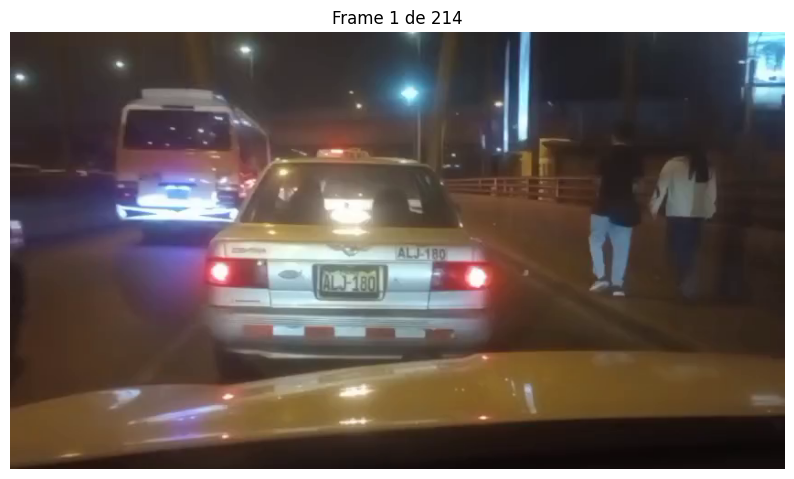

In [23]:
import cv2

VIDEO_PATH = "/content/videoplaca180526.mp4"
cap = cv2.VideoCapture(VIDEO_PATH)

fps    = cap.get(cv2.CAP_PROP_FPS)
nframes = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
w      = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h      = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
dur    = nframes / fps if fps > 0 else 0

print(f"📹 Video info")
print(f"   Resolución: {w} × {h} px")
print(f"   FPS:        {fps:.1f}")
print(f"   Frames:     {nframes}")
print(f"   Duración:   {dur:.1f} s")

# Mostrar el primer frame para confirmar que se lee bien
ret, frame = cap.read()
cap.release()

if ret:
    import matplotlib.pyplot as plt
    plt.figure(figsize=(10, 6))
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.title(f"Frame 1 de {nframes}")
    plt.axis('off')
    plt.show()
else:
    print("⚠️ No se pudo leer el primer frame")


 Procesar el video (detección + tracking + VLM + voto + anotación)


In [25]:
import cv2
from collections import defaultdict, Counter
import time

VIDEO_PATH  = "/content/videoplaca180526.mp4"
OUTPUT_PATH = "/content/video_anotado.mp4"
QUERY_EVERY = 5   # llamar al VLM cada N frames por placa (track)
CONF_YOLO   = 0.25

# --- Apertura del video ---
cap = cv2.VideoCapture(VIDEO_PATH)
fps = cap.get(cv2.CAP_PROP_FPS)
w   = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h   = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
n_total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

# --- Writer de salida (mp4v es el codec más compatible en Colab) ---
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter(OUTPUT_PATH, fourcc, fps, (w, h))

# --- Estado del tracking ---
track_readings  = defaultdict(Counter)   # track_id -> Counter de placas leídas
final_plates    = {}                     # track_id -> placa votada actual
last_query      = defaultdict(lambda: -999)
vlm_call_count  = 0

print(f"⏳ Procesando {n_total} frames (consulta VLM cada {QUERY_EVERY} frames por placa)...\n")
t_start = time.time()

frame_idx = 0
while True:
    ret, frame = cap.read()
    if not ret:
        break

    # YOLO + tracker (persist=True mantiene IDs entre frames)
    res = model.track(frame, persist=True, conf=CONF_YOLO,
                      tracker="bytetrack.yaml", verbose=False)[0]

    if res.boxes is not None and res.boxes.id is not None:
        boxes = res.boxes.xyxy.cpu().numpy().astype(int)
        ids   = res.boxes.id.cpu().numpy().astype(int)

        for (x1, y1, x2, y2), tid in zip(boxes, ids):
            # Consultar VLM solo cada N frames por track
            if frame_idx - last_query[tid] >= QUERY_EVERY:
                crop = frame[y1:y2, x1:x2]
                if crop.shape[0] > 15 and crop.shape[1] > 15:
                    respuesta = read_plate_vlm_v2(crop)
                    placa, _  = parse_vlm_smart(respuesta)
                    vlm_call_count += 1
                    if placa:
                        track_readings[tid][placa] += 1
                        final_plates[tid] = track_readings[tid].most_common(1)[0][0]
                last_query[tid] = frame_idx

            # Dibujar caja + texto (usa la placa votada actual)
            placa = final_plates.get(tid, "leyendo...")
            color = (0, 255, 0) if placa != "leyendo..." else (0, 200, 255)
            cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
            label = f"ID:{tid} {placa}"
            (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.7, 2)
            cv2.rectangle(frame, (x1, y1-th-12), (x1+tw+10, y1), color, -1)
            cv2.putText(frame, label, (x1+5, y1-6),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 0), 2)

    out.write(frame)
    frame_idx += 1
    if frame_idx % 30 == 0:
        elapsed = time.time() - t_start
        eta = elapsed * (n_total - frame_idx) / frame_idx
        print(f"  Frame {frame_idx:3d}/{n_total}  ({100*frame_idx/n_total:.0f}%)  "
              f"VLM calls: {vlm_call_count}  ETA: {eta:.0f}s")

cap.release()
out.release()

total_time = time.time() - t_start
print(f"\n✅ Video anotado: {OUTPUT_PATH}")
print(f"⏱️  Tiempo total: {total_time:.1f} s   |   VLM calls totales: {vlm_call_count}")
print(f"\n📋 Placas únicas identificadas en el video:")
for tid, conteo in track_readings.items():
    top3 = conteo.most_common(3)
    print(f"   Track #{tid:>2} → {final_plates.get(tid, '?'):<10}  (votos: {dict(top3)})")


⏳ Procesando 214 frames (consulta VLM cada 5 frames por placa)...

  Frame  30/214  (14%)  VLM calls: 6  ETA: 35s
  Frame  60/214  (28%)  VLM calls: 12  ETA: 31s
  Frame  90/214  (42%)  VLM calls: 18  ETA: 24s
  Frame 120/214  (56%)  VLM calls: 23  ETA: 18s
  Frame 150/214  (70%)  VLM calls: 29  ETA: 12s
  Frame 180/214  (84%)  VLM calls: 35  ETA: 7s
  Frame 210/214  (98%)  VLM calls: 40  ETA: 1s

✅ Video anotado: /content/video_anotado.mp4
⏱️  Tiempo total: 40.6 s   |   VLM calls totales: 41

📋 Placas únicas identificadas en el video:
   Track # 1 → ALJ-180     (votos: {'ALJ-180': 24, 'ALM-160': 2, 'ALN-160': 2})


In [32]:
import os, cv2, shutil, time
from collections import defaultdict, Counter

VIDEO_PATH  = "/content/videoplaca180526.mp4"
FRAMES_DIR  = "/content/frames_anot"
OUTPUT_PATH = "/content/video_play.mp4"
QUERY_EVERY = 5
CONF_YOLO   = 0.25

# Limpiar artefactos previos
if os.path.exists(FRAMES_DIR):
    shutil.rmtree(FRAMES_DIR)
os.makedirs(FRAMES_DIR)
for f in ["/content/video_anotado.mp4", "/content/video_play.mp4"]:
    if os.path.exists(f):
        os.remove(f)

cap = cv2.VideoCapture(VIDEO_PATH)
fps     = cap.get(cv2.CAP_PROP_FPS)
n_total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

track_readings = defaultdict(Counter)
final_plates   = {}
last_query     = defaultdict(lambda: -999)
vlm_calls = 0

print(f"⏳ Procesando {n_total} frames a {fps:.1f} FPS...\n")
t_start = time.time()
frame_idx = 0

while True:
    ret, frame = cap.read()
    if not ret:
        break

    res = model.track(frame, persist=True, conf=CONF_YOLO,
                      tracker="bytetrack.yaml", verbose=False)[0]

    if res.boxes is not None and res.boxes.id is not None:
        boxes = res.boxes.xyxy.cpu().numpy().astype(int)
        ids   = res.boxes.id.cpu().numpy().astype(int)

        for (x1, y1, x2, y2), tid in zip(boxes, ids):
            if frame_idx - last_query[tid] >= QUERY_EVERY:
                crop = frame[y1:y2, x1:x2]
                if crop.shape[0] > 15 and crop.shape[1] > 15:
                    respuesta = read_plate_vlm_v2(crop)
                    placa, _ = parse_vlm_smart(respuesta)
                    vlm_calls += 1
                    if placa:
                        track_readings[tid][placa] += 1
                        final_plates[tid] = track_readings[tid].most_common(1)[0][0]
                last_query[tid] = frame_idx

            placa = final_plates.get(tid, "leyendo...")
            color = (0, 255, 0) if placa != "leyendo..." else (0, 200, 255)
            cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
            label = f"ID:{tid} {placa}"
            (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.7, 2)
            cv2.rectangle(frame, (x1, y1-th-12), (x1+tw+10, y1), color, -1)
            cv2.putText(frame, label, (x1+5, y1-6),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 0), 2)

    # ★ Guardar cada frame como JPG (atómico, no se corrompe)
    cv2.imwrite(f"{FRAMES_DIR}/{frame_idx:05d}.jpg", frame,
                [cv2.IMWRITE_JPEG_QUALITY, 92])
    frame_idx += 1

    if frame_idx % 30 == 0:
        el = time.time() - t_start
        eta = el * (n_total - frame_idx) / frame_idx
        print(f"  Frame {frame_idx:3d}/{n_total}  ({100*frame_idx/n_total:.0f}%)  "
              f"VLM:{vlm_calls}  ETA:{eta:.0f}s")

cap.release()

# ★ Ensamblar con ffmpeg → H.264 directo (reproducible inline)
print("\n🎬 Ensamblando video con ffmpeg...")
!ffmpeg -y -loglevel error -framerate {fps} \
    -i {FRAMES_DIR}/%05d.jpg \
    -c:v libx264 -pix_fmt yuv420p -crf 23 \
    {OUTPUT_PATH}

# Limpieza de frames temporales
shutil.rmtree(FRAMES_DIR)

total = time.time() - t_start
print(f"\n✅ Video listo: {OUTPUT_PATH}")
!ls -lh {OUTPUT_PATH}
print(f"\n⏱️  Tiempo total: {total:.1f}s | VLM calls: {vlm_calls}")
print(f"\n📋 Placas únicas detectadas:")
for tid, conteo in track_readings.items():
    placa = final_plates.get(tid, "?")
    print(f"   Track #{tid:>2} → {placa:<10}  votos: {dict(conteo.most_common(3))}")


⏳ Procesando 214 frames a 29.6 FPS...

  Frame  30/214  (14%)  VLM:6  ETA:38s
  Frame  60/214  (28%)  VLM:12  ETA:32s
  Frame  90/214  (42%)  VLM:18  ETA:25s
  Frame 120/214  (56%)  VLM:23  ETA:18s
  Frame 150/214  (70%)  VLM:29  ETA:12s
  Frame 180/214  (84%)  VLM:35  ETA:7s
  Frame 210/214  (98%)  VLM:40  ETA:1s

🎬 Ensamblando video con ffmpeg...

✅ Video listo: /content/video_play.mp4
-rw-r--r-- 1 root root 781K May 19 01:39 /content/video_play.mp4

⏱️  Tiempo total: 47.6s | VLM calls: 41

📋 Placas únicas detectadas:
   Track # 1 → ALJ-180     votos: {'ALJ-180': 24, 'ALC-160': 1, 'ALB-800': 1}


In [33]:
from IPython.display import HTML
from base64 import b64encode

with open('/content/video_play.mp4', 'rb') as f:
    data = b64encode(f.read()).decode()

HTML(f"""<video width=720 controls autoplay loop>
  <source src="data:video/mp4;base64,{data}" type="video/mp4">
</video>""")
